# Index admission screen: Canadian serial acquirers

**Question:** which Canadian candidates deserve a place in the Serial Acquirers & Consolidators index, and why?

**Method:** compute the same measures, with the same definitions, for the current index members and for each candidate.
A candidate passes a test if it is at least as good as the **weaker quarter of current members** (25th percentile; leverage: 75th).
In plain words: *"it would not be the weakest company already in the index."* Then add the test no ratio can do: **does management deliver what it says?**

Data: standard financial statements (same definitions for all), deep profiles for deals and quotes, earnings call transcripts for claims.

## 1. Universe

In [1]:
import json, pathlib
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from profiles import load_all, load_statements, statement_scorecard

pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 220)

CANDIDATES = {"csu": "CSU.TO", "toi": "TOI.V", "tfii": "TFII.TO", "wsp": "WSP.TO", "aecon": "ARE.TO"}
NAMES = {"csu": "Constellation", "toi": "Topicus", "tfii": "TFI", "wsp": "WSP", "aecon": "Aecon"}
INDEX = ["AME", "WCN", "BRO", "IEX", "ETN", "ROP", "TDY", "TDG", "ACM", "HEI", "J", "POOL", "WSO", "DHR"]  # BSP (Italy) not pulled

idx_st = load_statements({t: t for t in INDEX})
can_st = load_statements(CANDIDATES)
idx = statement_scorecard(idx_st, years=3)
can = statement_scorecard(can_st, years=3)
can.insert(0, "name", can.index.map(NAMES)); idx.insert(0, "name", idx.index)
print(f"Index members loaded: {len(idx)} of {len(INDEX)}  |  candidates: {len(can)}")
missing = set(INDEX) - set(idx.index)
if missing: print("Missing (pull them or ignore):", sorted(missing))

Index members loaded: 14 of 14  |  candidates: 5


## 2. The current index, measured the same way

Sanity-check this table: if a member looks odd (e.g. negative equity making ROIC meaningless), note it. The 25th-percentile rule makes one odd member matter less.

In [2]:
MEASURES = {   # column: (label, higher_is_better, format)
    "reinvestment":       ("Reinvests FCF into acquisitions (x)", True,  "{:.2f}x"),
    "revenue_cagr":       ("Revenue growth per year, 3y",        True,  "{:.0%}"),
    "fcf_margin":         ("FCF margin, 3y",                       True,  "{:.0%}"),
    "roic":               ("ROIC, last year",                      True,  "{:.0%}"),
    "net_debt_to_ebitda": ("Net debt / EBITDA",                    False, "{:.1f}x"),
}
idx[["name"] + list(MEASURES)].round(3).sort_values("revenue_cagr", ascending=False)

,name,reinvestment,revenue_cagr,fcf_margin,roic,net_debt_to_ebitda
key,,,,,,
HEI,HEI,1.745,0.266,0.166,0.135,1.620
BRO,BRO,2.691,0.174,0.233,0.114,3.451
TDG,TDG,1.276,0.170,0.205,0.162,6.245
ROP,ROP,1.327,0.137,0.319,0.061,2.850
ETN,ETN,0.131,0.098,0.132,0.145,1.701
WCN,WCN,0.998,0.096,0.136,0.074,3.112
ACM,ACM,0.199,0.071,0.043,0.187,1.392
J,J,0.009,0.071,0.069,0.102,1.591
AME,AME,0.660,0.064,0.237,0.127,0.819


In [3]:
bench = pd.DataFrame({
    "index_p25": idx[list(MEASURES)].quantile(0.25),
    "index_median": idx[list(MEASURES)].median(),
    "index_p75": idx[list(MEASURES)].quantile(0.75),
})
bench["bar_to_pass"] = [bench.loc[c, "index_p25"] if MEASURES[c][1] else bench.loc[c, "index_p75"] for c in bench.index]
bench["label"] = [MEASURES[c][0] for c in bench.index]
bench.round(3)

,index_p25,index_median,index_p75,bar_to_pass,label
reinvestment,0.148,0.516,1.206,0.148,Reinvests FCF into acquisitions (x)
revenue_cagr,0.031,0.071,0.127,0.031,"Revenue growth per year, 3y"
fcf_margin,0.114,0.166,0.221,0.114,"FCF margin, 3y"
roic,0.081,0.120,0.158,0.081,"ROIC, last year"
net_debt_to_ebitda,1.437,1.660,2.703,2.703,Net debt / EBITDA


## 3. Admission tests

`RULE = 'p25'` (not weaker than the weakest quarter) or `'median'` (as good as a typical member). Stricter = fewer admissions.

In [4]:
RULE = "p25"
bar = bench["bar_to_pass"] if RULE == "p25" else bench["index_median"]

tests = pd.DataFrame(index=can.index)
for c, (label, up, fmt) in MEASURES.items():
    v = can[c]
    tests[c] = np.where(v.isna(), "n/a", np.where((v >= bar[c]) if up else (v <= bar[c]), "pass", "fail"))

# Test 6: does management deliver? (from claims.csv; built from earnings calls)
cl = pd.read_csv("output/claims.csv")
# "Abandoned" is not counted: walking away from a deal can be discipline
bad = cl["verdict"].str.contains("Behind|Changed course|At risk", case=False)
cred = cl.assign(bad=bad).groupby("key")["bad"].agg(["sum", "count"])
tests["delivers"] = [("no data" if k not in cred.index else ("fail" if cred.loc[k, "sum"] >= 2 else
                      "watch" if cred.loc[k, "sum"] == 1 else "pass")) for k in tests.index]

tests["passes"] = (tests == "pass").sum(axis=1)
tests["fails"] = (tests == "fail").sum(axis=1)
def verdict(r):
    if r["reinvestment"] == "fail": return "Not a serial acquirer"
    if r["fails"] == 0: return "Include"
    if r["fails"] <= 2 and r["delivers"] != "fail": return "Watchlist"
    return "Exclude for now"
tests["verdict"] = tests.apply(verdict, axis=1)
tests.insert(0, "name", tests.index.map(NAMES))
tests

,name,reinvestment,revenue_cagr,fcf_margin,roic,net_debt_to_ebitda,delivers,passes,fails,verdict
key,,,,,,,,,,
aecon,Aecon,fail,pass,fail,fail,pass,pass,3,3,Not a serial acquirer
csu,Constellation,pass,pass,pass,pass,pass,pass,6,0,Include
tfii,TFI,pass,pass,fail,fail,fail,fail,2,4,Exclude for now
toi,Topicus,pass,pass,pass,pass,pass,no data,5,0,Include
wsp,WSP,pass,pass,fail,pass,pass,watch,4,1,Watchlist


## 4. Where each candidate sits against the index

Grey dots = current index members. Blue = Canadian candidates. Shaded = the weaker quarter of the index (below the bar to pass).

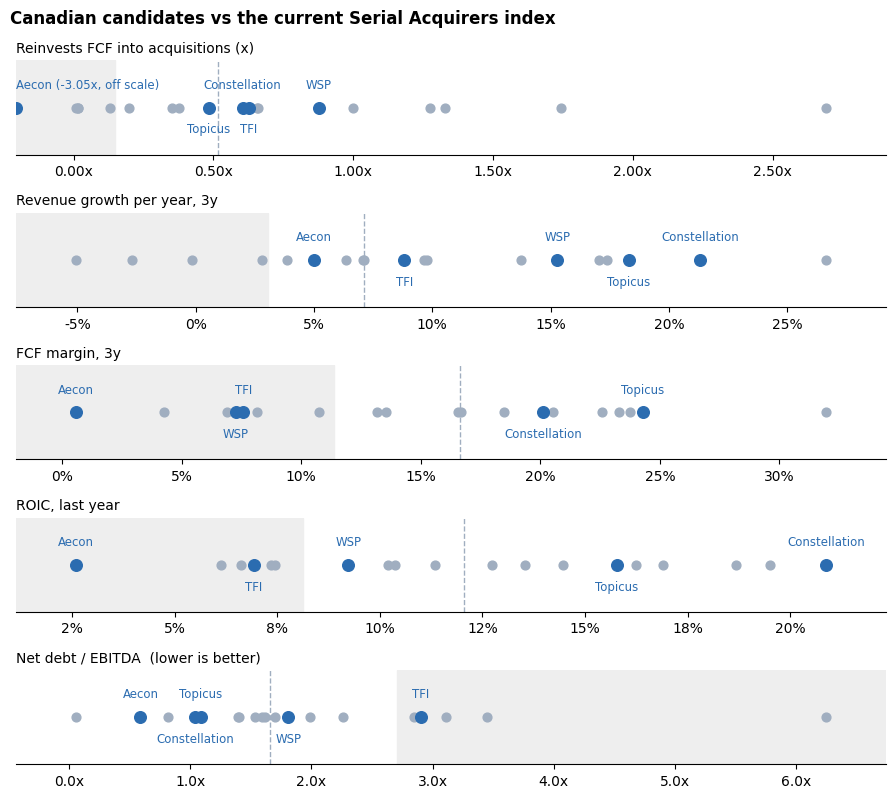

In [5]:
from matplotlib.ticker import FuncFormatter
cols = list(MEASURES)
fig, axes = plt.subplots(len(cols), 1, figsize=(9, 1.5 * len(cols) + 0.6))
for ax, c in zip(axes, cols):
    label, up, fmt = MEASURES[c]
    iv, cv = idx[c].dropna(), can[c].dropna()
    span = iv.max() - iv.min()
    near = cv[(cv >= iv.min() - span) & (cv <= iv.max() + span)]   # a far-off candidate is clipped, not stretched
    lo, hi = min(iv.min(), near.min()), max(iv.max(), near.max())
    pad = (hi - lo) * 0.08 or 0.1; lo, hi = lo - pad, hi + pad
    b = bar[c]
    ax.axvspan(lo, b, color="#eee") if up else ax.axvspan(b, hi, color="#eee")
    ax.scatter(iv.clip(lo, hi), np.zeros(len(iv)), color="#a0aec0", s=40, zorder=2)
    ax.axvline(bench.loc[c, "index_median"], color="#a0aec0", lw=1, ls="--")
    for i, (k, v) in enumerate(cv.sort_values().items()):   # alternate above/below in value order
        x = np.clip(v, lo, hi); txt = NAMES[k] + (f" ({fmt.format(v)}, off scale)" if v < lo or v > hi else "")
        ax.scatter([x], [0], color="#2b6cb0", s=70, zorder=3)
        ax.annotate(txt, (x, 0), xytext=(0, 14 if i % 2 == 0 else -18), textcoords="offset points",
                    ha="left" if v < lo else "center", fontsize=8.5, color="#2b6cb0")
    ax.set_xlim(lo, hi); ax.set_ylim(-1, 1); ax.set_yticks([])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _, f=fmt: f.format(x)))
    ax.set_title(label + ("" if up else "  (lower is better)"), loc="left", fontsize=10)
    for s_ in ("top", "right", "left"): ax.spines[s_].set_visible(False)
fig.suptitle("Canadian candidates vs the current Serial Acquirers index", x=0.01, ha="left", fontsize=12, weight="bold")
plt.tight_layout(); plt.show()

## 5. Why include / why not: one card per candidate

In [6]:
prof = load_all(); m, deals = prof["metrics"], prof["deals"]

def fmtv(c, v): return "n/a" if pd.isna(v) else MEASURES[c][2].format(v)

def card(k):
    r, t = can.loc[k], tests.loc[k]
    print(f"=== {NAMES[k]} ({CANDIDATES[k]}) → {t['verdict'].upper()}")
    for c, (label, up, fmt) in MEASURES.items():
        mark = {"pass": "✓", "fail": "✗"}.get(t[c], "·")
        print(f"  {mark} {label}: {fmtv(c, r[c])}  (index median {fmtv(c, bench.loc[c, 'index_median'])}, bar {fmtv(c, bar[c])})")
    nd = deals[(deals["key"] == k) & ~deals["is_aggregate"] & deals["is_dated"]]
    print(f"  · Named, dated acquisitions in filings: {len(nd)}" + (f" (latest: {nd.sort_values('date').iloc[-1]['counterparty'] or 'unnamed'})" if len(nd) else ""))
    org = m[(m["key"] == k) & m["metric_id"].str.contains("organic", na=False)].sort_values("report_date")
    if len(org): print(f"  · Organic growth (latest, company-reported): {org.iloc[-1]['value']:.0%}  \"{org.iloc[-1]['quote'][:90]}\"")
    c2 = cl[cl["key"] == k]
    if len(c2):
        print(f"  {'✓' if t['delivers']=='pass' else '✗' if t['delivers']=='fail' else '!'} Management delivers: " +
              "; ".join(f"{a} ({b})" for a, b in zip(c2["target"], c2["verdict"])))
    else:
        print("  · Management delivers: no recent earnings calls in the data")
    print()

for k in tests.sort_values("passes", ascending=False).index: card(k)

=== Constellation (CSU.TO) → INCLUDE
  ✓ Reinvests FCF into acquisitions (x): 0.60x  (index median 0.52x, bar 0.15x)
  ✓ Revenue growth per year, 3y: 21%  (index median 7%, bar 3%)
  ✓ FCF margin, 3y: 20%  (index median 17%, bar 11%)
  ✓ ROIC, last year: 21%  (index median 12%, bar 8%)
  ✓ Net debt / EBITDA: 1.0x  (index median 1.7x, bar 2.7x)
  · Named, dated acquisitions in filings: 9 (latest: DerbySoft Holdings Limited)
  · Organic growth (latest, company-reported): 3%  "the Company experienced organic growth of 3% and 4% respectively"
  ✓ Management delivers: Keep deploying into acquisitions rather than buybacks (no NCIB) (Kept); Lift margins of newly acquired businesses (Kept (self-reported))

=== Topicus (TOI.V) → INCLUDE
  ✓ Reinvests FCF into acquisitions (x): 0.48x  (index median 0.52x, bar 0.15x)
  ✓ Revenue growth per year, 3y: 18%  (index median 7%, bar 3%)
  ✓ FCF margin, 3y: 24%  (index median 17%, bar 11%)
  ✓ ROIC, last year: 16%  (index median 12%, bar 8%)
  ✓ Net debt

## 6. Peer check: WSP vs its direct index peers (AECOM, Jacobs)

In [7]:
peers = [p for p in ["ACM", "J"] if p in idx.index]
if "wsp" in can.index and peers:
    pc = pd.concat([can.loc[["wsp"], list(MEASURES)].rename(index={"wsp": "WSP"}), idx.loc[peers, list(MEASURES)]])
    display(pc.round(3))

,reinvestment,revenue_cagr,fcf_margin,roic,net_debt_to_ebitda
key,,,,,
WSP,0.878,0.153,0.073,0.092,1.810
ACM,0.199,0.071,0.043,0.187,1.392
J,0.009,0.071,0.069,0.102,1.591


## 7. Export

In [8]:
out = pathlib.Path("output"); out.mkdir(exist_ok=True)
with pd.ExcelWriter(out / "index_screen.xlsx") as xl:
    tests.to_excel(xl, sheet_name="admission_tests")
    can.to_excel(xl, sheet_name="candidates")
    idx.to_excel(xl, sheet_name="index_members")
    bench.to_excel(xl, sheet_name="benchmarks")
print("Saved", out / "index_screen.xlsx")

Saved output\index_screen.xlsx
